# Bài thực hành chương 1 – Xử lý ảnh cơ bản với OpenCV và Pillow
**Môn:** Computer Vision  |  **Nhóm:** Computer-Vision-Group-2  |  **File:** `Lab01_Final.ipynb`

Notebook tổng hợp 6 phần của nhóm, chạy từ đầu đến cuối với một ảnh mẫu duy nhất.

| Mục | Nội dung | Thành viên | Notebook chi tiết | Source |
|---|---|---|---|---|
| 1 | Đọc, kiểm tra, hiển thị ảnh | TV1 | `01_read_display` | `image_io.py` |
| 2 | Pillow, lưu và đổi định dạng | TV2 | `02_image_io_pillow` | `image_io.py` |
| 3 | Grayscale, HSV, LAB | TV3, TV4 | `03_grayscale`, `04_hsv_lab` | `color_space.py` |
| 4 | Crop và Resize | TV5 | `05_crop_resize` | `transform.py` |
| 5 | Vẽ hình và thêm văn bản | TV6 | `06_drawing_text` | `drawing.py` |

## 0. Cài đặt thư viện và cấu hình
Cài bằng `pip install opencv-python pillow matplotlib numpy` (hoặc `pip install -r requirements.txt`).

In [1]:
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import PIL
from PIL import Image

sys.path.append(str(Path("..") / "src"))
import image_io as io
import color_space as cs
import transform as tf

from image_io import find_input_image
INPUT = find_input_image("06_animal_lion.jpg")   # ảnh trong data/input (tự chọn ảnh khác nếu không thấy)
OUT = Path("../data/output"); OUT.mkdir(parents=True, exist_ok=True)

print("OpenCV :", cv2.__version__)
print("Pillow :", PIL.__version__)
print("NumPy  :", np.__version__)

def rgb(img):  # OpenCV là BGR, Matplotlib là RGB
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

OpenCV : 4.13.0
Pillow : 12.2.0
NumPy  : 2.4.6


## 1. Đọc, kiểm tra và hiển thị ảnh (OpenCV)

Shape=(256, 256, 3)  (H=256, W=256, C=3)  dtype=uint8


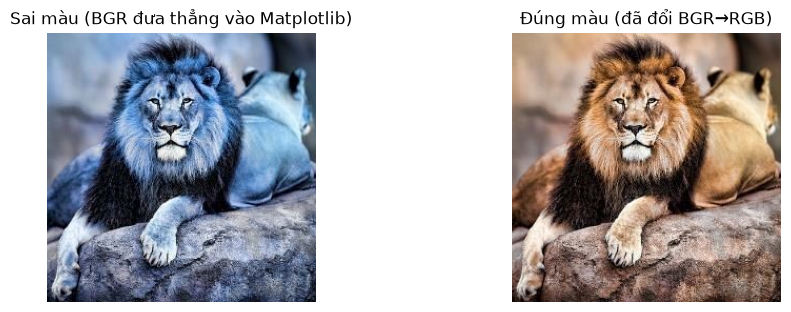

In [2]:
image = io.read_image(INPUT)
assert image is not None, "Không đọc được ảnh"
info = io.get_image_info(image)
print(f"Shape={info['shape']}  (H={info['height']}, W={info['width']}, C={info['channels']})  dtype={info['dtype']}")

plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1); plt.imshow(image);      plt.title("Sai màu (BGR đưa thẳng vào Matplotlib)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(rgb(image)); plt.title("Đúng màu (đã đổi BGR→RGB)"); plt.axis("off")
plt.show()

- `cv2.imread()` trả về `None` nếu sai đường dẫn nên phải kiểm tra trước khi dùng.
- `shape = (height, width, channels)`; ảnh 8-bit có giá trị 0–255.
- OpenCV lưu kênh theo thứ tự **BGR** (quy ước lịch sử), Matplotlib hiển thị **RGB** nên phải đổi khi vẽ.

## 2. Pillow, lưu ảnh và đổi định dạng

In [3]:
pil = io.read_image_pillow(INPUT)
pi = io.get_pillow_info(pil)
print(f"Pillow: size={pi['size']} (width, height), mode={pi['mode']}, format={pi['format']}")

paths = {"JPG gốc": INPUT,
         "PNG":  io.convert_format(INPUT, OUT / f"{INPUT.stem}.png"),
         "WEBP": io.convert_format(INPUT, OUT / f"{INPUT.stem}.webp"),
         "BMP":  io.convert_format(INPUT, OUT / f"{INPUT.stem}.bmp")}
for name, p in paths.items():
    print(f"{name:8s} {io.file_size_kb(p):9.1f} KB")

Pillow: size=(256, 256) (width, height), mode=RGB, format=JPEG
JPG gốc       22.1 KB
PNG          131.0 KB
WEBP          17.2 KB
BMP          192.1 KB


- Pillow: `size = (width, height)`, RGB. OpenCV: `shape = (height, width, channels)`, BGR. Hai thứ tự ngược nhau nên dễ nhầm.
- **JPG** nén mất thông tin (nhỏ), **PNG** nén không mất thông tin, **BMP** gần như không nén (lớn nhất).
- Pillow mạnh ở đọc/ghi và đổi định dạng; OpenCV mạnh ở xử lý ảnh và thị giác máy tính.

## 3. Chuyển đổi không gian màu: Grayscale, HSV, LAB

Màu : (256, 256, 3) | Gray: (256, 256) | HSV: (256, 256, 3) | LAB: (256, 256, 3)
Khoảng giá trị HSV: {'H': (0, 179), 'S': (0, 255), 'V': (0, 255)}


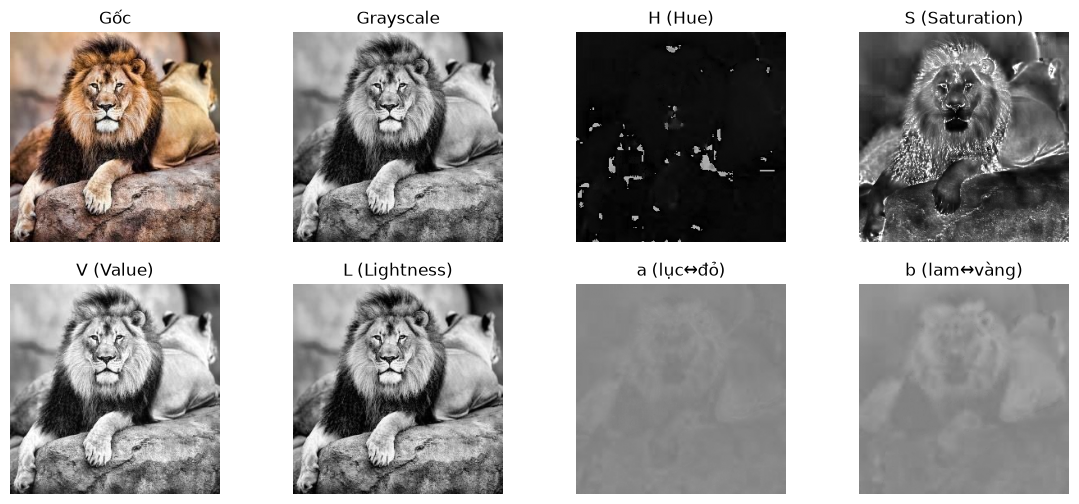

In [4]:
gray = cs.bgr_to_gray(image)
hsv  = cs.bgr_to_hsv(image)
lab  = cs.bgr_to_lab(image)
print("Màu :", image.shape, "| Gray:", gray.shape, "| HSV:", hsv.shape, "| LAB:", lab.shape)
print("Khoảng giá trị HSV:", cs.channel_ranges(hsv, ["H", "S", "V"]))

h, s, v = cv2.split(hsv); l, a, b = cv2.split(lab)
items = [(rgb(image), "Gốc"), (gray, "Grayscale"), (h, "H (Hue)"), (s, "S (Saturation)"),
         (v, "V (Value)"), (l, "L (Lightness)"), (a, "a (lục↔đỏ)"), (b, "b (lam↔vàng)")]
plt.figure(figsize=(14, 6))
for i, (im, t) in enumerate(items, 1):
    plt.subplot(2, 4, i)
    plt.imshow(im) if i == 1 else plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(t); plt.axis("off")
plt.show()

- **Grayscale** `(H, W)`: 1 kênh, tính theo `0.299R + 0.587G + 0.114B` (không phải chỉ lấy một kênh).
- **HSV** = Hue (loại màu), Saturation (độ rực), Value (độ sáng); `H` của OpenCV nằm trong 0–179. Phù hợp để tách vật theo màu.
- **LAB** = Lightness + `a` (lục↔đỏ) + `b` (lam↔vàng); `a`, `b` lệch 128. Gần cảm nhận màu của mắt người.
- Chuyển không gian màu là **tính lại giá trị pixel**, không phải đổi thứ tự kênh. Hiển thị thẳng mảng HSV/LAB sẽ sai màu vì Matplotlib coi 3 kênh là RGB.

## 4. Crop và Resize

Gốc         shape=(256, 256, 3)  W/H=1.00
Crop        shape=(153, 128, 3)  W/H=0.84
Resize 50%  shape=(128, 128, 3)  W/H=1.00
Giữ tỷ lệ   shape=(300, 300, 3)  W/H=1.00
Ép 300x300  shape=(300, 300, 3)  W/H=1.00


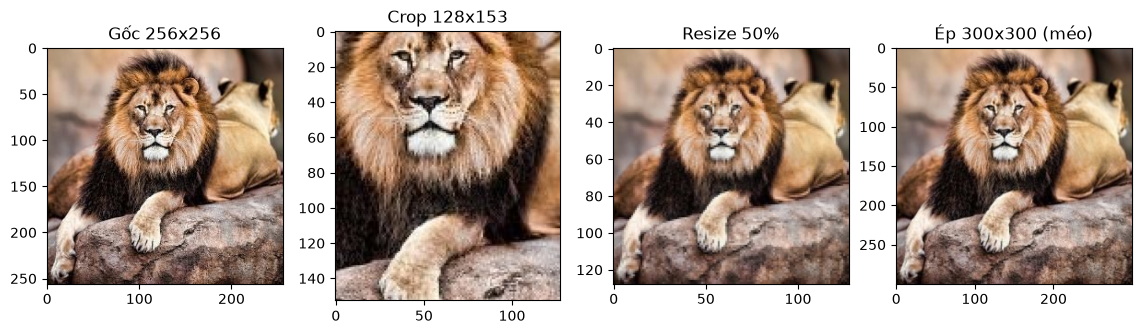

In [5]:
H, W = image.shape[:2]
crop = tf.crop_image(image, int(0.25 * W), int(0.20 * H), int(0.75 * W), int(0.80 * H))   # image[y1:y2, x1:x2]
half = tf.resize_by_scale(image, 0.5)                    # giữ tỷ lệ
fixed_ok  = tf.resize_keep_ratio(image, width=300)       # giữ tỷ lệ
fixed_bad = tf.resize_fixed(image, 300, 300)             # ép vuông -> méo

for n, im in [("Gốc", image), ("Crop", crop), ("Resize 50%", half), ("Giữ tỷ lệ", fixed_ok), ("Ép 300x300", fixed_bad)]:
    print(f"{n:11s} shape={im.shape}  W/H={tf.aspect_ratio(im):.2f}")

plt.figure(figsize=(14, 3.5))
for i, (im, t) in enumerate([(image, f"Gốc {W}x{H}"), (crop, f"Crop {crop.shape[1]}x{crop.shape[0]}"), (half, "Resize 50%"), (fixed_bad, "Ép 300x300 (méo)")], 1):
    plt.subplot(1, 4, i); plt.imshow(rgb(im)); plt.title(t)
plt.show()

- Crop dùng slicing `image[y1:y2, x1:x2]` (**hàng trước, cột sau**); `y` là hàng, `x` là cột.
- `cv2.resize` nhận `(width, height)`, ngược thứ tự với `shape`.
- Đổi tỷ lệ `width/height` làm ảnh **méo**; muốn giữ hình dạng thì dùng cùng hệ số cho hai chiều. Thu nhỏ nên dùng `INTER_AREA`.

## 5. Vẽ hình cơ bản và thêm văn bản

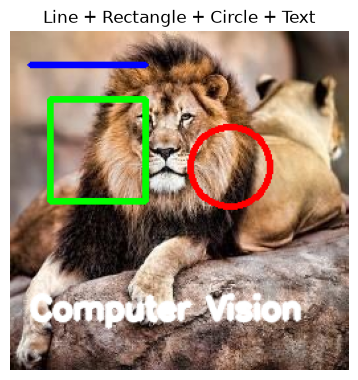

In [6]:
H, W = image.shape[:2]
px = lambda fx, fy: (int(fx * W), int(fy * H))   # đổi tỷ lệ (0-1) thành tọa độ (x, y)
T, FS = max(3, W // 300), max(0.8, W / 800)       # độ dày nét, cỡ chữ theo kích thước ảnh
canvas = image.copy()
cv2.line(canvas, px(0.06, 0.10), px(0.40, 0.10), (255, 0, 0), T)           # đường thẳng
cv2.rectangle(canvas, px(0.12, 0.20), px(0.40, 0.50), (0, 255, 0), T)      # hình chữ nhật
cv2.circle(canvas, px(0.65, 0.40), int(0.12 * W), (0, 0, 255), T)          # hình tròn
cv2.putText(canvas, "Computer Vision", px(0.06, 0.85),
            cv2.FONT_HERSHEY_SIMPLEX, FS, (255, 255, 255), T, cv2.LINE_AA)  # văn bản
cv2.imwrite(str(OUT / f"{INPUT.stem}_drawing.jpg"), canvas)

plt.figure(figsize=(7, 4.4)); plt.imshow(rgb(canvas)); plt.title("Line + Rectangle + Circle + Text"); plt.axis("off"); plt.show()

- Gốc tọa độ `(0, 0)` ở **góc trên-trái**, `x` sang phải, `y` xuống dưới; điểm viết dạng `(x, y)`.
- Màu theo **BGR**: `(255, 0, 0)` là xanh dương. `thickness` là độ dày nét, `-1` là tô đặc.
- `putText` lấy góc **dưới-trái** của chữ làm điểm đặt, không hiển thị được tiếng Việt có dấu.

## 6. Tổng kết chương 1
| Thao tác | Hàm chính | Lưu ý quan trọng |
|---|---|---|
| Đọc ảnh | `cv2.imread`, `Image.open` | `imread` trả `None` khi lỗi |
| Hiển thị | `plt.imshow` | Đổi BGR→RGB; ảnh xám dùng `cmap="gray"` |
| Lưu / đổi định dạng | `cv2.imwrite`, `Image.save` | JPG mất thông tin, PNG không mất |
| Đổi không gian màu | `cv2.cvtColor` | HSV: H 0–179; LAB: a, b lệch 128 |
| Crop | `image[y1:y2, x1:x2]` | Hàng trước, cột sau |
| Resize | `cv2.resize` | `(width, height)`; giữ tỷ lệ để không méo |
| Vẽ / chữ | `line`, `rectangle`, `circle`, `putText` | Màu BGR, tọa độ `(x, y)` |

**Kết luận**
- Ảnh số là mảng NumPy `(H, W, C)` gồm các pixel; mọi thao tác ở chương này đều là xử lý trên mảng đó.
- Hai nguồn lỗi hay gặp nhất: **thứ tự kênh BGR/RGB** và **thứ tự chiều** (`shape` là H, W; `size` của Pillow và `resize` là W, H).
- OpenCV phù hợp xử lý ảnh, Pillow phù hợp đọc/ghi và đổi định dạng; có thể chuyển qua lại bằng NumPy.
- Các kiến thức này là nền tảng cho các chương sau (phát hiện cạnh, đặc trưng, nhận dạng).